# Where has bus demand fallen since 2023-24, and did it hold up near the Elizabeth line?

BUSTO starts in 2023-24, after the Elizabeth line opened, so a before/after comparison for buses is
not possible. The EDA found that weekday bus boardings fell about 7% between 2023-24 and 2025-26,
but only about 1% at stops near Elizabeth line stations. This notebook asks:

1. **Where and when** did bus demand fall: by area, distance from rail, time of day and day type?
2. **How much is route changes and service cuts** rather than passengers?
3. **Did demand hold up better near the Elizabeth line** once geography, route changes and
   service levels are accounted for?

Unit of analysis: a **route-stop** (route, direction, stop) with its average daily boardings in
2023-24 and 2025-26. "Near" means within 400 m of a station; "rail" is TfL rail.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
con = B.busto_con()
q = lambda sql: con.execute(sql).df()
Y0, Y1 = 2023, 2025
pct = lambda x: 100 * (np.exp(x) - 1)

rail = B.rail_stations()
EL_CENTRAL = ['Paddington', 'Bond Street', 'Tottenham Court Road', 'Farringdon', 'Liverpool Street',
              'Whitechapel', 'Canary Wharf', 'Custom House', 'Woolwich', 'Abbey Wood']   # opened May 2022
EL_ALL = list(rail.index[rail['lines'].str.contains('Elizabeth')])
EL_BRANCH = [s for s in EL_ALL if s not in EL_CENTRAL]   # served by TfL Rail before 2022
stops = B.load_stops()

## 1. Route changes, service cuts and passengers

In [2]:
rs = q(f'''SELECT year, day_type, route, direction, stopcode,
                  sum(boardings) AS b, sum(capacity) AS cap
           FROM qhr WHERE year IN ({Y0}, {Y1}) GROUP BY ALL''')
w = rs.pivot_table(index=['day_type', 'route', 'direction', 'stopcode'], columns='year', values=['b', 'cap'])
w.columns = [f'{a}{b}' for a, b in w.columns]
w = w.reset_index()

rows = []
for dt, g in w.groupby('day_type'):
    cont = g.dropna(subset=[f'b{Y0}', f'b{Y1}'])
    rows.append({
        'day type': dt,
        f'total {Y0}-{str(Y0 + 1)[2:]} (M)': g[f'b{Y0}'].sum() / 1e6,
        'total change (%)': 100 * (g[f'b{Y1}'].sum() / g[f'b{Y0}'].sum() - 1),
        'continuing route-stops (%)': 100 * (cont[f'b{Y1}'].sum() / cont[f'b{Y0}'].sum() - 1),
        'capacity on continuing route-stops (%)': 100 * (cont[f'cap{Y1}'].sum() / cont[f'cap{Y0}'].sum() - 1),
        'added route-stops (M)': g.loc[g[f'b{Y0}'].isna(), f'b{Y1}'].sum() / 1e6,
        'withdrawn route-stops (M)': -g.loc[g[f'b{Y1}'].isna(), f'b{Y0}'].sum() / 1e6,
    })
decomp = pd.DataFrame(rows).set_index('day type').loc[B.DAY_TYPES].round(3)
decomp.to_csv(B.RESULTS / 'bus_change_decomposition.csv')
decomp

,total 2023-24 (M),total change (%),continuing route-stops (%),capacity on continuing route-stops (%),added route-stops (M),withdrawn route-stops (M)
day type,,,,,,
Weekday,5.706,-6.742,-7.771,-3.325,0.147,-0.096
Saturday,4.695,-5.625,-6.540,-2.378,0.117,-0.079
Sunday,3.417,-2.327,-3.508,-0.412,0.092,-0.054


On every day type, demand on route-stops served in both years fell by more than the total:
added routes (notably the Superloop) slightly more than offset withdrawn ones. The fall is a fall in
passengers on the existing network, not an artefact of route changes.

**Service levels.** Capacity (seats + standing space passing each stop) on the same route-stops
fell too. Routes whose capacity fell more lost more passengers:

594 routes. Elasticity of demand to capacity: 0.59 (95% CI 0.43 to 0.74); demand change at unchanged capacity: -6.1%
median route capacity change -1.7%; routes cut by more than 10%: 75, increased by more than 10%: 31


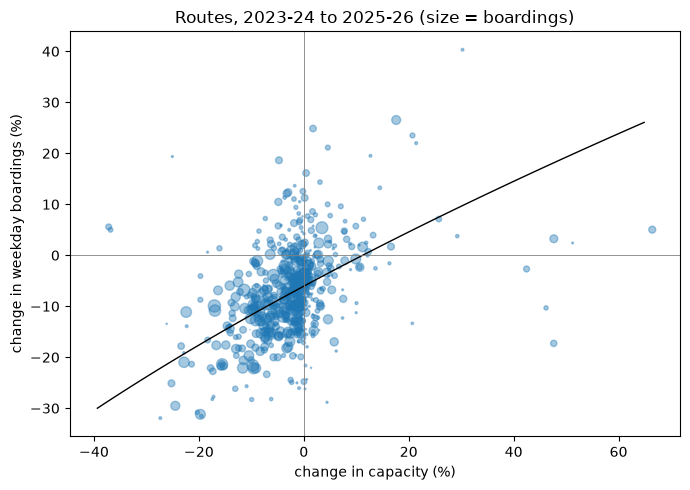

In [3]:
wd = w[(w.day_type == 'Weekday')].dropna(subset=[f'b{Y0}', f'b{Y1}'])
r = wd.groupby('route')[[f'b{Y0}', f'b{Y1}', f'cap{Y0}', f'cap{Y1}']].sum()
r['demand'] = np.log(r[f'b{Y1}'] / r[f'b{Y0}'])
r['capacity'] = np.log(r[f'cap{Y1}'] / r[f'cap{Y0}'])
r['type'] = [B.route_type(x) for x in r.index]
m_sup = smf.wls('demand ~ capacity', data=r, weights=r[f'b{Y0}']).fit(cov_type='HC1')
print(f"{len(r)} routes. Elasticity of demand to capacity: {m_sup.params['capacity']:.2f} "
      f"(95% CI {m_sup.conf_int().loc['capacity', 0]:.2f} to {m_sup.conf_int().loc['capacity', 1]:.2f}); "
      f"demand change at unchanged capacity: {pct(m_sup.params['Intercept']):.1f}%")
print(f"median route capacity change {pct(r.capacity.median()):.1f}%; "
      f"routes cut by more than 10%: {(r.capacity < np.log(.9)).sum()}, increased by more than 10%: {(r.capacity > np.log(1.1)).sum()}")

fig, ax = plt.subplots(figsize=(7, 5))
lim = (r.capacity.abs() < .6) & (r.demand.abs() < .6)
ax.scatter(pct(r.capacity[lim]), pct(r.demand[lim]), s=r[f'b{Y0}'][lim] / 400, alpha=.4)
xs = np.linspace(-.5, .5, 50)
ax.plot(pct(xs), pct(m_sup.params['Intercept'] + m_sup.params['capacity'] * xs), 'k-', lw=1)
ax.axhline(0, color='grey', lw=.6); ax.axvline(0, color='grey', lw=.6)
ax.set_xlabel('change in capacity (%)'); ax.set_ylabel('change in weekday boardings (%)')
ax.set_title(f'Routes, {Y0}-{str(Y0 + 1)[2:]} to {Y1}-{str(Y1 + 1)[2:]} (size = boardings)')
plt.tight_layout(); plt.show()

About 0.6% of demand is lost for each 1% of capacity removed, but even routes with unchanged
capacity lost about 6%: service cuts explain only part of the fall.

## 2. Where and when did demand fall?

Continuing route-stops only, so route changes do not distort the comparison.

In [4]:
cont = w.dropna(subset=[f'b{Y0}', f'b{Y1}']).join(stops[['lat', 'lon']], on='stopcode').dropna(subset=['lat'])
u = cont[['stopcode', 'lat', 'lon']].drop_duplicates('stopcode').set_index('stopcode')
nr = B.nearest_rail(u, rail)
links = {rad: B.bus_rail_links(u, rail, rad) for rad in B.WALK_RADII_M}

def near(stations, radius=B.WALK_M):
    lk = links[radius]
    return cont['stopcode'].isin(lk.loc[lk.station.isin(stations), 'stopcode'])

cont['dist_rail'] = cont['stopcode'].map(nr['dist_m'])
cont['from_centre'] = pd.cut(B.haversine_m(cont.lat, cont.lon, 51.5080, -0.1246) / 1000, [0, 3, 6, 10, 15, 50],
                             labels=['0-3 km', '3-6 km', '6-10 km', '10-15 km', '15+ km'])
cont['to_rail'] = pd.cut(cont['dist_rail'], [0, 400, 800, 2000, np.inf], right=False,
                         labels=['< 400 m', '400-800 m', '800 m - 2 km', '> 2 km'])
cont['route_type'] = cont['route'].map(B.route_type)
cont['near'] = np.select([near(EL_CENTRAL), near(EL_BRANCH), near(rail.index)],
                         ['Elizabeth line, central section', 'Elizabeth line, outer branches', 'other TfL rail'],
                         'not near TfL rail')

def change(df, by):
    g = df.groupby(by, observed=True)[[f'b{Y0}', f'b{Y1}']].sum()
    return (100 * (g[f'b{Y1}'] / g[f'b{Y0}'] - 1)).round(1)

tabs = {}
for by in ['from_centre', 'to_rail', 'near', 'route_type']:
    tabs[by] = pd.DataFrame({dt: change(cont[cont.day_type == dt], by) for dt in B.DAY_TYPES})
    tabs[by].index.name = by
    display(tabs[by].assign(**{f'weekday boardings {Y0}-{str(Y0 + 1)[2:]} (000s)':
                               (cont[cont.day_type == 'Weekday'].groupby(by, observed=True)[f'b{Y0}'].sum() / 1e3).round(0)}))
pd.concat(tabs, names=['grouping', 'group']).to_csv(B.RESULTS / 'bus_change_by_group.csv')

,Weekday,Saturday,Sunday,weekday boardings 2023-24 (000s)
from_centre,,,,
0-3 km,-7.7,-7.0,-2.3,507.0
3-6 km,-10.5,-10.1,-7.6,856.0
6-10 km,-8.3,-6.7,-4.0,1221.0
10-15 km,-7.0,-5.3,-2.7,1499.0
15+ km,-6.5,-4.8,-1.3,1512.0


,Weekday,Saturday,Sunday,weekday boardings 2023-24 (000s)
to_rail,,,,
< 400 m,-7.6,-6.4,-3.1,2401.0
400-800 m,-8.9,-7.5,-4.9,1106.0
800 m - 2 km,-7.9,-6.2,-3.8,1290.0
> 2 km,-6.1,-5.7,-1.8,799.0


,Weekday,Saturday,Sunday,weekday boardings 2023-24 (000s)
near,,,,
"Elizabeth line, central section",-6.8,-7.0,-3.0,141.0
"Elizabeth line, outer branches",-2.2,-1.0,3.9,195.0
not near TfL rail,-7.8,-6.6,-3.7,3194.0
other TfL rail,-8.2,-6.8,-3.8,2066.0


,Weekday,Saturday,Sunday,weekday boardings 2023-24 (000s)
route_type,,,,
letter prefix,-6.5,-3.6,-1.5,562.0
night,-8.2,-7.5,-3.0,59.0
numbered,-8.0,-6.9,-3.8,4928.0
superloop,3.2,1.5,8.8,47.0


In [5]:
tod = q(f'''SELECT year, day_type, hour(qhr) AS hour, route, direction, stopcode, sum(boardings) AS b
            FROM qhr WHERE year IN ({Y0}, {Y1}) GROUP BY ALL''')
key = cont[['day_type', 'route', 'direction', 'stopcode']]
tod = tod.merge(key, on=['day_type', 'route', 'direction', 'stopcode'])      # continuing route-stops
bands = pd.cut(tod.hour, [-1, 4, 6, 9, 15, 18, 21, 23],
               labels=['00-05 night', '05-07 early', '07-10 AM peak', '10-16 inter-peak',
                       '16-19 PM peak', '19-22 evening', '22-24 late'])
t = tod.assign(band=bands).pivot_table(index=['day_type', 'band'], columns='year', values='b', aggfunc='sum', observed=True)
by_time = (100 * (t[Y1] / t[Y0] - 1)).round(1).unstack(0)[B.DAY_TYPES]
by_time.to_csv(B.RESULTS / 'bus_change_by_time.csv')
by_time

day_type,Weekday,Saturday,Sunday
band,,,
00-05 night,-12.9,-9.8,-4.0
05-07 early,-8.0,-7.1,-3.7
07-10 AM peak,-8.3,-3.7,-1.3
10-16 inter-peak,-8.1,-7.2,-3.2
16-19 PM peak,-6.5,-6.8,-4.3
19-22 evening,-5.3,-4.6,-2.7
22-24 late,-11.1,-6.9,-8.6


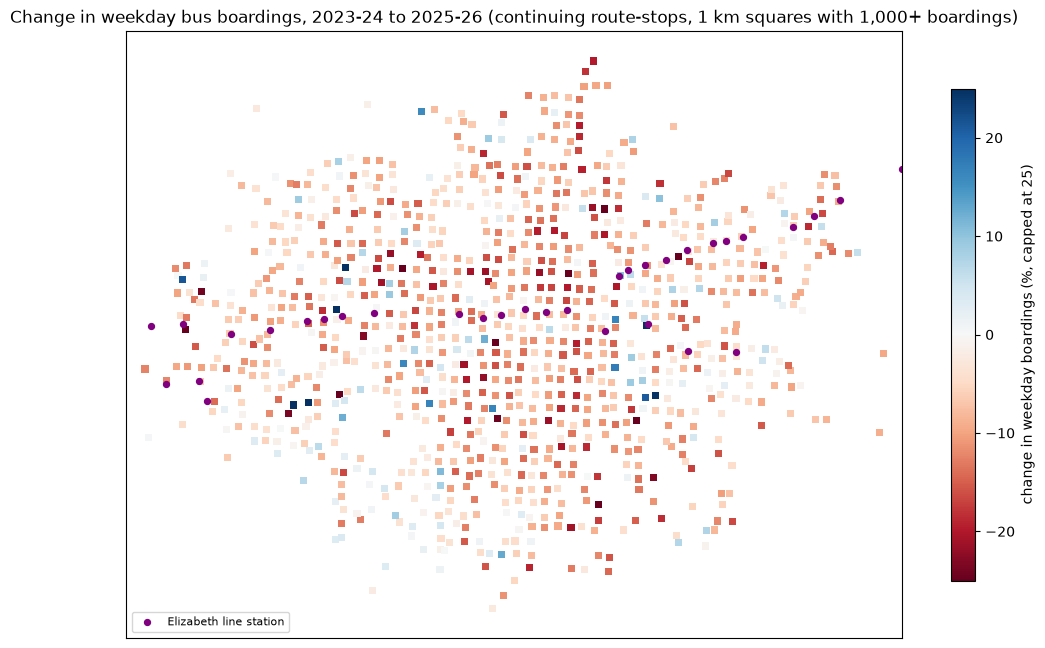

In [6]:
# Map: change in weekday boardings on continuing route-stops, 1 km grid squares
wd = cont[cont.day_type == 'Weekday'].join(stops[['easting', 'northing']], on='stopcode')
wd['cell'] = list(zip((wd.easting // 1000).astype(int), (wd.northing // 1000).astype(int)))
cells = wd.groupby('cell')[[f'b{Y0}', f'b{Y1}', 'lat', 'lon']].agg(
    {f'b{Y0}': 'sum', f'b{Y1}': 'sum', 'lat': 'mean', 'lon': 'mean'})
cells = cells[cells[f'b{Y0}'] >= 1000]
cells['chg'] = 100 * (cells[f'b{Y1}'] / cells[f'b{Y0}'] - 1)

fig, ax = plt.subplots(figsize=(10, 8.5))
sc = ax.scatter(cells.lon, cells.lat, c=cells.chg.clip(-25, 25), cmap='RdBu', vmin=-25, vmax=25,
                s=26, marker='s', lw=0)
el = rail.loc[EL_ALL]
ax.scatter(el.lon, el.lat, s=18, color='purple', marker='o', label='Elizabeth line station')
ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlim(cells.lon.min() - .02, cells.lon.max() + .02); ax.set_ylim(cells.lat.min() - .02, cells.lat.max() + .02)
plt.colorbar(sc, ax=ax, shrink=.6, label='change in weekday boardings (%, capped at 25)')
ax.legend(loc='lower left', fontsize=8)
ax.set_title(f'Change in weekday bus boardings, {Y0}-{str(Y0 + 1)[2:]} to {Y1}-{str(Y1 + 1)[2:]} '
             '(continuing route-stops, 1 km squares with 1,000+ boardings)')
plt.tight_layout(); plt.show()

## 3. Did demand hold up better near the Elizabeth line?

The raw comparison above mixes several things: Elizabeth line stations are spread from central
London to the outer suburbs, where demand fell least, and routes serving them may have had
different service changes. A regression on continuing weekday route-stops separates these:

$$\Delta\log(\text{boardings}) = \beta_1\,\text{near EL central} + \beta_2\,\text{near EL branch}
+ \beta_3\,\text{near other rail} + \text{distance ring} + \gamma\,\Delta\log(\text{capacity})
\;[+\;\text{route-direction fixed effects}]$$

The comparison group is stops not near TfL rail. With **route-direction fixed effects**, stops are
compared only with other stops on the same route, so anything that affected a whole route (frequency
changes, reliability, rerouting elsewhere on the route) cancels out. Weighted by 2023-24 boardings;
route-stops with fewer than 5 boardings a day in 2023-24 dropped; standard errors clustered by route.

In [7]:
def regression_data(day_type='Weekday', radius=B.WALK_M, min_b=5):
    d = cont[(cont.day_type == day_type) & (cont[f'b{Y0}'] >= min_b) & (cont[f'b{Y1}'] > 0)].copy()
    lk = links[radius]
    near_ = lambda S: d['stopcode'].isin(lk.loc[lk.station.isin(S), 'stopcode'])
    d['el_central'] = near_(EL_CENTRAL).astype(int)
    d['el_branch'] = (near_(EL_BRANCH) & ~near_(EL_CENTRAL)).astype(int)
    d['other_rail'] = (near_(rail.index) & ~near_(EL_ALL)).astype(int)
    d['dlog_b'] = np.log(d[f'b{Y1}'] / d[f'b{Y0}'])
    d['dlog_cap'] = np.log(d[f'cap{Y1}'] / d[f'cap{Y0}'])
    d['ring'] = d['from_centre'].astype(str)
    d['rd'] = d['route'] + '_' + d['direction'].astype(str)
    return d

SPECS = {
    '(1) raw': 'dlog_b ~ el_central + el_branch + other_rail',
    '(2) + ring': 'dlog_b ~ el_central + el_branch + other_rail + C(ring)',
    '(3) + ring + capacity': 'dlog_b ~ el_central + el_branch + other_rail + C(ring) + dlog_cap',
    '(4) + ring + route FE': 'dlog_b ~ el_central + el_branch + other_rail + C(ring) + C(rd)',
    '(5) + ring + capacity + route FE': 'dlog_b ~ el_central + el_branch + other_rail + C(ring) + dlog_cap + C(rd)',
}

def fit(d, formula):
    m = smf.wls(formula, data=d, weights=d[f'b{Y0}']).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(d['route'])[0]})
    out = {}
    for v in ['el_central', 'el_branch', 'other_rail']:
        lo, hi = m.conf_int().loc[v]
        out[v] = f"{pct(m.params[v]):+.1f}% [{pct(lo):+.1f}, {pct(hi):+.1f}]"
    return out

d = regression_data()
print(f"{len(d):,} weekday route-stops on {d.route.nunique()} routes; near EL central: {d.el_central.sum()}, "
      f"EL branch: {d.el_branch.sum()}, other rail: {d.other_rail.sum()}")
main = pd.DataFrame({name: fit(d, f) for name, f in SPECS.items()}).T
main.columns = ['near EL central section', 'near EL outer branches', 'near other TfL rail']
main.to_csv(B.RESULTS / 'bus_change_near_el_regression.csv')
main

40,314 weekday route-stops on 594 routes; near EL central: 542, EL branch: 679, other rail: 10276


,near EL central section,near EL outer branches,near other TfL rail
(1) raw,"-0.2% [-3.4, +3.1]","+3.3% [+0.2, +6.5]","-2.6% [-4.2, -1.0]"
(2) + ring,"+2.1% [-1.3, +5.6]","+2.4% [-0.6, +5.5]","-0.6% [-2.0, +0.8]"
(3) + ring + capacity,"+2.3% [-1.1, +5.7]","+2.8% [-0.4, +6.0]","-0.8% [-2.2, +0.6]"
(4) + ring + route FE,"+2.7% [-0.8, +6.3]","+2.4% [-0.7, +5.7]","-1.1% [-2.6, +0.5]"
(5) + ring + capacity + route FE,"+2.6% [-0.8, +6.2]","+2.4% [-0.8, +5.7]","-1.1% [-2.6, +0.5]"


Each cell: change in boardings relative to stops not near TfL rail, with 95% confidence interval.

### Robustness

In [8]:
f5 = SPECS['(5) + ring + capacity + route FE']
f4 = SPECS['(4) + ring + route FE']
rob = {
    'main: weekday, 400 m, spec (5)': fit(regression_data(), f5),
    'spec (4): no capacity control': fit(regression_data(), f4),
    'within 200 m': fit(regression_data(radius=200), f5),
    'within 800 m': fit(regression_data(radius=800), f5),
    'Saturday': fit(regression_data('Saturday'), f5),
    'Sunday': fit(regression_data('Sunday'), f5),
    'route-stops with 20+ boardings': fit(regression_data(min_b=20), f5),
}
rob = pd.DataFrame(rob).T
rob.columns = ['near EL central section', 'near EL outer branches', 'near other TfL rail']
rob.to_csv(B.RESULTS / 'bus_change_near_el_robustness.csv')
rob

,near EL central section,near EL outer branches,near other TfL rail
"main: weekday, 400 m, spec (5)","+2.6% [-0.8, +6.2]","+2.4% [-0.8, +5.7]","-1.1% [-2.6, +0.5]"
spec (4): no capacity control,"+2.7% [-0.8, +6.3]","+2.4% [-0.7, +5.7]","-1.1% [-2.6, +0.5]"
within 200 m,"+7.6% [+2.5, +12.9]","+6.1% [+2.2, +10.3]","-0.4% [-2.3, +1.6]"
within 800 m,"+0.9% [-2.8, +4.7]","+0.6% [-2.2, +3.5]","-0.7% [-2.2, +0.8]"
Saturday,"+1.8% [-1.6, +5.3]","+1.6% [-2.2, +5.5]","-0.9% [-2.5, +0.6]"
Sunday,"+2.5% [-0.7, +5.7]","+3.4% [-0.9, +7.8]","-0.4% [-2.0, +1.3]"
route-stops with 20+ boardings,"+2.7% [-0.8, +6.4]","+2.4% [-0.8, +5.7]","-1.0% [-2.6, +0.6]"


## Summary

* **The fall is real, not route changes.** Weekday boardings fell 6.7% (Saturday 5.6%, Sunday 2.3%). On
  route-stops served in both years the fall was larger (-7.8%); new routes, mainly the Superloop,
  slightly outweighed withdrawals.
* **Service cuts explain part of it.** Capacity on continuing route-stops fell 3.3% on weekdays; demand
  falls about 0.6% per 1% of capacity removed, but routes with unchanged capacity still lost about 6%.
* **Where and when:** the fall is widespread. It is largest 3-6 km from the centre (-10.5% on weekdays)
  and at night (-13%), smallest in the evening (-5%) and on Sundays. Superloop routes grew (+3%).
* **Near the Elizabeth line.** The EDA's gap (-1.5% near the line vs -7.1% elsewhere) is partly new
  routes: on continuing route-stops it is -4.1% vs -8.0%. Once distance from the centre, capacity and
  route are controlled for, stops near the line did about **2-3% better** than stops away from rail,
  not clearly different from zero at 400 m. The advantage is concentrated at the stations' doorstep:
  **+7.6% within 200 m** of a central-section station (95% CI +2.5 to +12.9), +0.9% within 800 m. Stops near
  other TfL rail stations did no better than stops away from rail.
* **Answer:** bus demand fell across London since 2023-24, most in inner London and at night. It held up
  slightly better right next to Elizabeth line stations, consistent with buses feeding the line, but
  most of the apparent difference near the line comes from geography and new routes.